# Missing Category Imputation

Missing category imputation consists of replacing missing values in categorical variables with an explicit label such as **`"Missing"`**, **`"Unknown"`**, or **`"None"`**.

Instead of guessing what the missing value might be, this technique treats missingness itself as an additional, distinct category.

---

## Learning Objectives
By the end of this notebook, you will be able to:
1. Understand why creating a `"Missing"` category is often superior to mode imputation when missingness is substantial.
2. Identify when missing values represent a genuine **absence of a feature** (e.g., no fireplace, no garage) rather than unrecorded data.
3. Apply missing category imputation using both **pandas** and **scikit-learn's `SimpleImputer`**.
4. Visualize how category proportions are preserved without distorting observed categories.

---
## 1. When to Use Missing Category Imputation

### Ideal Use Cases:
1. **High Missingness (> 10-20%)**: Where mode imputation would heavily distort category proportions.
2. **Missing Not at Random (MNAR) / Absence of a Feature**:
   - In house price datasets, missing values in `FireplaceQu`, `Alley`, or `PoolQC` usually mean the property has **no fireplace, no alley, and no pool**.
   - Replacing these NaNs with `"Missing"` or `"None"` accurately reflects the domain reality!
3. **Preserving Information**: Allows downstream models (e.g., decision trees or linear models with one-hot encoding) to learn an explicit parameter/weight for the missing state.

### Important Considerations:
- If missingness is very rare (e.g., only 1 or 2 rows out of 10,000), creating a separate `"Missing"` category creates an extremely rare category that may cause high variance or unseen category issues during cross-validation. For such rare cases, **mode imputation** is preferred.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Matplotlib styling
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['font.size'] = 10

---
## 2. Loading Data & Splitting Train/Test Sets

We examine categorical features from the Ames House Prices dataset with notable missingness:
- **`BsmtQual`**: Basement height quality (~2.5% missing - no basement).
- **`FireplaceQu`**: Fireplace quality (~47% missing - no fireplace).

In [2]:
cols_to_use = [
    "BsmtQual",
    "FireplaceQu",
    "SalePrice",
]

data_path = '../datasets/houseprice.csv'
if not os.path.exists(data_path):
    data_path = 'https://raw.githubusercontent.com/cmps460s26/cmps460-content/refs/heads/main/examples/03.dp/datasets/houseprice.csv'

data = pd.read_csv(data_path, usecols=cols_to_use)

# Split into predictors and target
X = data.drop("SalePrice", axis=1)
y = data["SalePrice"]

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")

X_train shape: (1022, 2)
X_test shape:  (438, 2)


---
## 3. Inspecting Missing Data Proportions

Let's check the missing data percentage in `X_train`.

In [3]:
# Missing data summary in X_train
missing_summary = pd.DataFrame({
    'Null Count': X_train.isnull().sum(),
    'Null Percentage': X_train.isnull().mean() * 100
})
missing_summary

,Null Count,Null Percentage
BsmtQual,24,2.348337
FireplaceQu,478,46.771037


---
## 4. Method 1: Imputation Using Pandas

With pandas, we use `.fillna("Missing")` on both `X_train` and `X_test`.

In [4]:
# Create explicit copies
X_train_pd = X_train.copy()
X_test_pd = X_test.copy()

# Fill missing values with 'Missing'
X_train_pd.fillna('Missing', inplace=True)
X_test_pd.fillna('Missing', inplace=True)

# Corroborate that no nulls remain
print(f"Remaining nulls in X_train: {X_train_pd.isnull().sum().to_dict()}")
print(f"Remaining nulls in X_test:  {X_test_pd.isnull().sum().to_dict()}")

Remaining nulls in X_train: {'BsmtQual': 0, 'FireplaceQu': 0}
Remaining nulls in X_test:  {'BsmtQual': 0, 'FireplaceQu': 0}


In [5]:
# Inspect unique categories after imputation
print("Categories in FireplaceQu after imputation:")
print(X_train_pd['FireplaceQu'].value_counts())

Categories in FireplaceQu after imputation:
FireplaceQu
Missing    478
Gd         255
TA         229
Fa          26
Ex          18
Po          16
Name: count, dtype: int64


---
## 5. Method 2: Imputation Using Scikit-Learn `SimpleImputer`

With scikit-learn, we set `strategy='constant'` and `fill_value='Missing'`. This can be integrated directly into a `Pipeline` or `ColumnTransformer`.

In [6]:
# Set up SimpleImputer with constant fill_value
imputer = SimpleImputer(strategy='constant', fill_value='Missing')
imputer.set_output(transform="pandas")

# Fit on training set and transform both sets
imputer.fit(X_train)
X_train_sk = imputer.transform(X_train)
X_test_sk = imputer.transform(X_test)

# Verify clean DataFrame output
print(f"Nulls in X_train_sk: {X_train_sk.isnull().sum().sum()}")
print(f"Nulls in X_test_sk:  {X_test_sk.isnull().sum().sum()}")
X_train_sk.head()

Nulls in X_train_sk: 0
Nulls in X_test_sk:  0


,BsmtQual,FireplaceQu
64,Gd,Missing
682,Gd,Gd
960,TA,Missing
1384,TA,Missing
1100,TA,Missing


---
## 6. Evaluating Distribution Impact

Let's visualize the category frequencies before and after adding the `"Missing"` category.

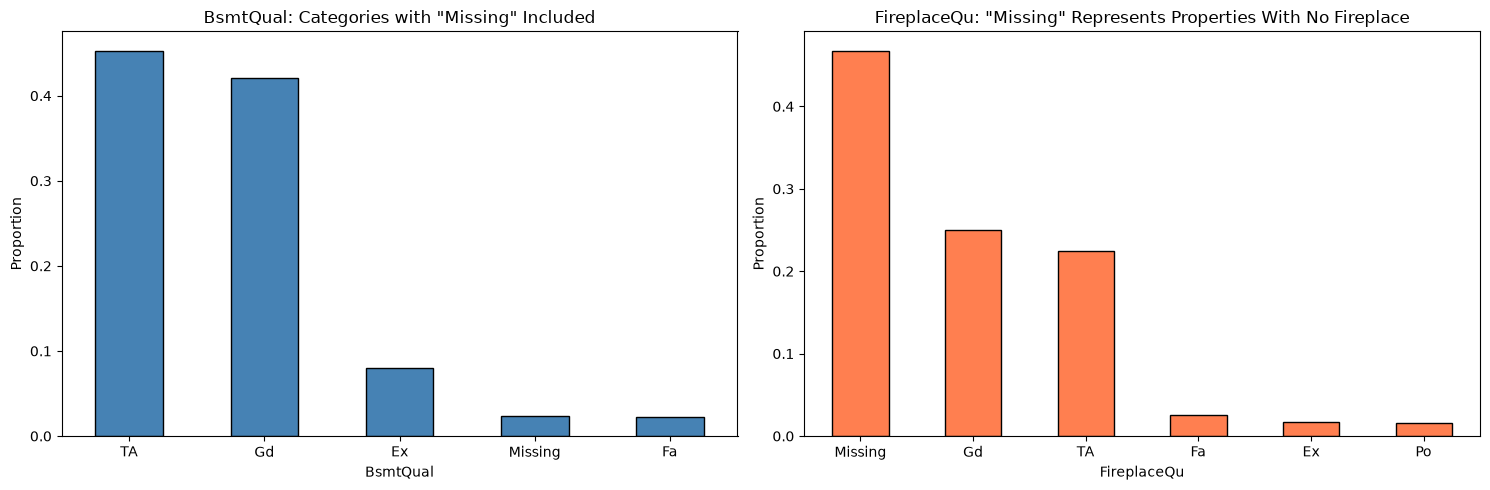

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot BsmtQual
X_train_sk['BsmtQual'].value_counts(normalize=True).plot(
    kind='bar', ax=ax1, color='steelblue', edgecolor='black'
)
ax1.set_title('BsmtQual: Categories with "Missing" Included')
ax1.set_ylabel('Proportion')
ax1.tick_params(axis='x', rotation=0)

# Plot FireplaceQu
X_train_sk['FireplaceQu'].value_counts(normalize=True).plot(
    kind='bar', ax=ax2, color='coral', edgecolor='black'
)
ax2.set_title('FireplaceQu: "Missing" Represents Properties With No Fireplace')
ax2.set_ylabel('Proportion')
ax2.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

### Key Takeaways:
1. **Preserved True Ranks**: Unlike mode imputation, which falsely labeled 47% of homes as having "Good" fireplaces, `"Missing"` stands on its own.
2. **Realistic Meaning**: Downstream algorithms learn that homes with `"Missing"` lack a fireplace, which accurately correlates with lower market value.

---
## 7. Summary & Best Practices Checklist

| Consideration | Recommendation |
| :--- | :--- |
| **When to Use** | Categorical features where missingness is high ($> 10\%$) or where absence is meaningful. |
| **When NOT to Use** | Very rare missingness ($< 1\%$) where creating a new category introduces an unhelpfully rare label. |
| **Downstream Compatibility** | Seamlessly works with One-Hot Encoding and Ordinal Encoding in scikit-learn. |
| **Pipeline Integration** | Use `SimpleImputer(strategy='constant', fill_value='Missing')`. |
